# UTS Intelegensi Buatan — Kasus 3: Klasifikasi Spesies Penguin
**Nama:** ______________________  **NIM:** 23552011428  **Kelas:** TIF RP 23D

Klasifikasi spesies penguin (Adelie, Chinstrap, Gentoo) menggunakan dataset `kasus03_penguins.csv`.

## 1. Persiapan Data

In [ ]:
!pip install -q streamlit joblib

In [2]:
import os, urllib.request
os.makedirs("dataset", exist_ok=True)
os.makedirs("models", exist_ok=True)
CSV = "dataset/kasus03_penguins.csv"
URL = ("https://raw.githubusercontent.com/Muhammad-Ikhwan-Fathulloh/"
       "Artificial-Intelegent-Course-Bank/main/UTS/dataset/kasus03_penguins.csv")
if not os.path.exists(CSV):
    try:
        urllib.request.urlretrieve(URL, CSV)
    except Exception as e:
        print("Unduh otomatis gagal:", e, "\nUnggah file CSV secara manual:")
        from google.colab import files
        up = files.upload()
        os.replace(next(iter(up)), CSV)
print("Dataset siap:", CSV)

Dataset siap: dataset/kasus03_penguins.csv


## 2. Feature Engineering

In [3]:
%%writefile fitur.py
import numpy as np
import pandas as pd

TARGET = "species"

FITUR_NUM_MENTAH = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
FITUR_KAT_MENTAH = ["island", "sex"]
FITUR_MENTAH = FITUR_KAT_MENTAH + FITUR_NUM_MENTAH

FITUR_TURUNAN = ["bill_ratio", "flipper_mass_ratio"]
FITUR_NUM = FITUR_NUM_MENTAH + FITUR_TURUNAN
FITUR_KAT = FITUR_KAT_MENTAH

KOLOM_DIBUANG = ["year"]
KATEGORI_SEX_HILANG = "unknown"


def audit_data(df: pd.DataFrame) -> dict:
    num = df[FITUR_NUM_MENTAH]
    return {
        "bentuk": df.shape,
        "duplikat_baris_penuh": int(df.duplicated().sum()),
        "missing_per_kolom": df.isna().sum()[lambda s: s > 0].to_dict(),
        "baris_semua_ukuran_kosong": int(num.isna().all(axis=1).sum()),
        "nilai_tidak_positif": int((num <= 0).sum().sum()),
        "tipe_data": df.dtypes.astype(str).to_dict(),
        "kategori_sex": df["sex"].value_counts(dropna=False).to_dict(),
        "distribusi_kelas": df[TARGET].value_counts().to_dict(),
    }


def bersihkan(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for c in ["island", "sex", TARGET]:
        if c in df.columns:
            df[c] = df[c].astype("object").where(df[c].notna(), np.nan)
            df[c] = df[c].str.strip()
    df["sex"] = df["sex"].str.lower()
    df = df.drop_duplicates()
    df[FITUR_NUM_MENTAH] = df[FITUR_NUM_MENTAH].where(df[FITUR_NUM_MENTAH] > 0)
    df = df[~df[FITUR_NUM_MENTAH].isna().all(axis=1)]
    return df.reset_index(drop=True)


def tambah_fitur(X: pd.DataFrame) -> pd.DataFrame:
    X = X.copy()
    depth = X["bill_depth_mm"].replace(0, np.nan)
    mass = X["body_mass_g"].replace(0, np.nan)
    X["bill_ratio"] = X["bill_length_mm"] / depth
    X["flipper_mass_ratio"] = X["flipper_length_mm"] / mass * 1000
    return X


Writing fitur.py


## 3. Eksplorasi Data

In [4]:
import pandas as pd, numpy as np
import fitur as F

df_mentah = pd.read_csv("dataset/kasus03_penguins.csv")
for k, v in F.audit_data(df_mentah).items():
    print(f"{k}: {v}")
df = F.bersihkan(df_mentah)
print("\nSetelah pembersihan:", df_mentah.shape, "->", df.shape)
display(df_mentah[df_mentah.isna().any(axis=1)])

bentuk: (344, 8)
duplikat_baris_penuh: 0
missing_per_kolom: {'bill_length_mm': 2, 'bill_depth_mm': 2, 'flipper_length_mm': 2, 'body_mass_g': 2, 'sex': 11}
baris_semua_ukuran_kosong: 2
nilai_tidak_positif: 0
tipe_data: {'species': 'str', 'island': 'str', 'bill_length_mm': 'float64', 'bill_depth_mm': 'float64', 'flipper_length_mm': 'float64', 'body_mass_g': 'float64', 'sex': 'str', 'year': 'int64'}
kategori_sex: {'male': 168, 'female': 165, nan: 11}
distribusi_kelas: {'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68}

Setelah pembersihan: (344, 8) -> (342, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN,2007
218,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN,2008
256,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN,2009
268,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN,2009


In [5]:
# Rata-rata ukuran per spesies dan sebaran data
print(df.groupby("species")[F.FITUR_NUM_MENTAH].mean().round(1), "\n")
print(pd.crosstab(df["island"], df["species"]), "\n")
print(pd.crosstab(df["year"], df["species"]), "\n")
print(F.tambah_fitur(df).groupby("species")[F.FITUR_TURUNAN].mean().round(2))

           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie               38.8           18.3              190.0       3700.7
Chinstrap            48.8           18.4              195.8       3733.1
Gentoo               47.5           15.0              217.2       5076.0 

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     123
Dream          56         68       0
Torgersen      51          0       0 

species  Adelie  Chinstrap  Gentoo
year                              
2007         49         26      34
2008         50         18      46
2009         52         24      43 

           bill_ratio  flipper_mass_ratio
species                                  
Adelie           2.12               52.01
Chinstrap        2.65               52.89
Gentoo           3.18               43.12


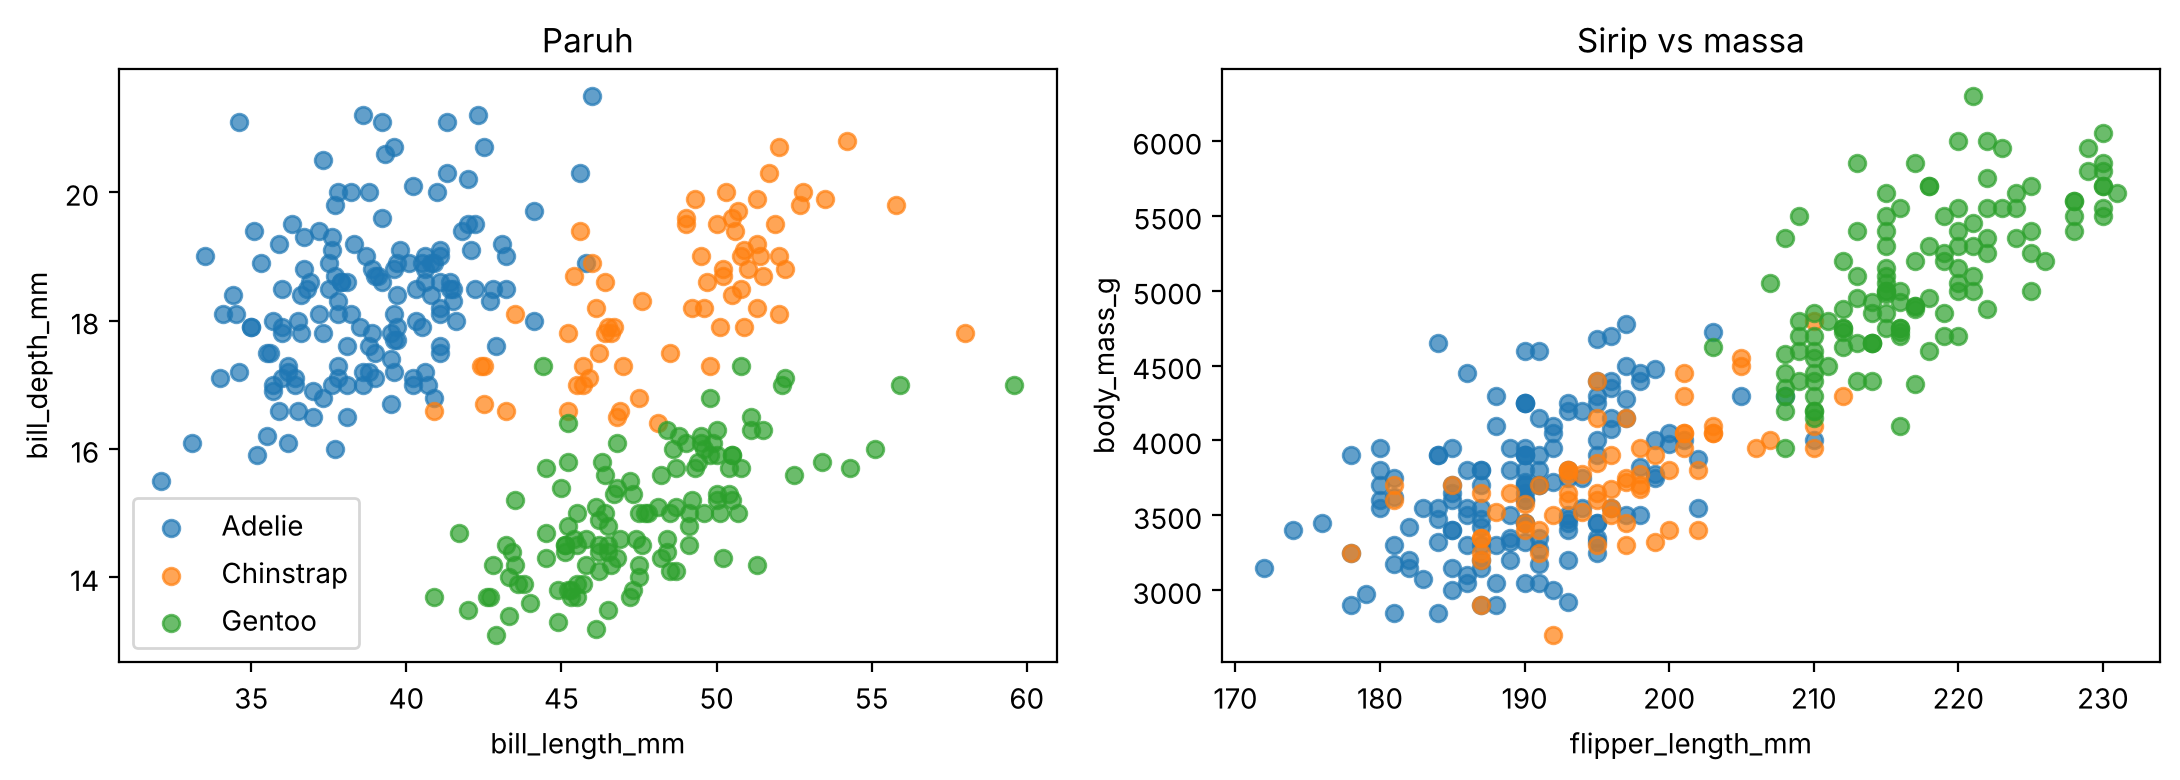

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for sp, g in df.groupby("species"):
    ax[0].scatter(g["bill_length_mm"], g["bill_depth_mm"], label=sp, alpha=.7)
    ax[1].scatter(g["flipper_length_mm"], g["body_mass_g"], label=sp, alpha=.7)
ax[0].set(xlabel="bill_length_mm", ylabel="bill_depth_mm", title="Paruh")
ax[1].set(xlabel="flipper_length_mm", ylabel="body_mass_g", title="Sirip vs massa")
ax[0].legend(); plt.tight_layout(); plt.show()

## 4. Pelatihan dan Evaluasi Model

In [7]:
%%writefile latih.py
from pathlib import Path

import joblib
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

import fitur as F

RANDOM_STATE = 42
BASE = Path(__file__).parent
DATA_PATH = BASE / "dataset" / "kasus03_penguins.csv"
MODEL_PATH = BASE / "models" / "penguins.joblib"


def buat_preprocess() -> ColumnTransformer:
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), F.FITUR_NUM),
        ("kat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value=F.KATEGORI_SEX_HILANG)),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), F.FITUR_KAT),
    ])


def buat_pipeline(clf) -> Pipeline:
    return Pipeline([
        ("fitur", FunctionTransformer(F.tambah_fitur, validate=False)),
        ("prep", buat_preprocess()),
        ("clf", clf),
    ])


def main() -> None:
    # 1. Load & audit data
    df_mentah = pd.read_csv(DATA_PATH)
    print("=== Audit Data Mentah ===")
    for k, v in F.audit_data(df_mentah).items():
        print(f"  {k}: {v}")

    df = F.bersihkan(df_mentah)
    print(f"\nSetelah pembersihan: {df_mentah.shape} -> {df.shape}")

    X = df[F.FITUR_MENTAH].copy()
    y = df[F.TARGET].astype(str)

    # 2. Split train/test
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    print(f"Data Train: {len(X_train)} | Data Test: {len(X_test)}")

    # 3. Bandingkan model dengan cross-validation
    kandidat = {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=5),
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    hasil_cv = {}

    print("\n=== Cross-Validation (5-Fold) ===")
    for nama, clf in kandidat.items():
        s = cross_validate(buat_pipeline(clf), X_train, y_train, cv=cv,
                           scoring=["accuracy", "f1_macro", "balanced_accuracy"])
        hasil_cv[nama] = {
            "accuracy": float(s["test_accuracy"].mean()),
            "f1_macro": float(s["test_f1_macro"].mean()),
            "f1_macro_std": float(s["test_f1_macro"].std()),
            "balanced_accuracy": float(s["test_balanced_accuracy"].mean()),
        }
        h = hasil_cv[nama]
        print(f"  {nama:<20} Accuracy: {h['accuracy']:.4f} | F1-macro: {h['f1_macro']:.4f} (+/-{h['f1_macro_std']:.4f})")

    terbaik = max(hasil_cv, key=lambda n: hasil_cv[n]["f1_macro"])
    print(f"\nModel terbaik: {terbaik}")

    # 4. Latih model terbaik dan evaluasi pada data test
    model = buat_pipeline(kandidat[terbaik]).fit(X_train, y_train)
    kelas = list(model.classes_)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=kelas)
    metrik = {
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
        "f1_macro": float(f1_score(y_test, y_pred, average="macro")),
        "f1_weighted": float(f1_score(y_test, y_pred, average="weighted")),
        "roc_auc_ovr_macro": float(roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro", labels=kelas)),
        "confusion_matrix": cm.tolist(),
        "laporan": classification_report(y_test, y_pred, labels=kelas, output_dict=True),
        "n_train": int(len(X_train)),
        "n_test": int(len(X_test)),
    }

    print("\n=== Evaluasi Data Test ===")
    print(classification_report(y_test, y_pred, labels=kelas, digits=3))
    print("Confusion Matrix:")
    print(pd.DataFrame(cm, index=kelas, columns=kelas))

    # 5. Simpan bundle model
    bundle = {
        "pipeline": model,
        "model_terpilih": terbaik,
        "fitur_mentah": F.FITUR_MENTAH,
        "kelas": kelas,
        "opsi": {
            "island": sorted(X_train["island"].dropna().unique().tolist()),
            "sex": sorted(X_train["sex"].dropna().unique().tolist()) + [F.KATEGORI_SEX_HILANG],
        },
        "rentang": {c: [float(X_train[c].min()), float(X_train[c].max()),
                        float(X_train[c].median())] for c in F.FITUR_NUM_MENTAH},
        "metrik_test": metrik,
        "hasil_cv": hasil_cv,
    }

    MODEL_PATH.parent.mkdir(exist_ok=True)
    joblib.dump(bundle, MODEL_PATH)
    print(f"\nModel tersimpan di: {MODEL_PATH}")


if __name__ == "__main__":
    main()


Writing latih.py


In [8]:
!python latih.py

=== Audit Data Mentah ===
  bentuk: (344, 8)
  duplikat_baris_penuh: 0
  missing_per_kolom: {'bill_length_mm': 2, 'bill_depth_mm': 2, 'flipper_length_mm': 2, 'body_mass_g': 2, 'sex': 11}
  baris_semua_ukuran_kosong: 2
  nilai_tidak_positif: 0
  tipe_data: {'species': 'str', 'island': 'str', 'bill_length_mm': 'float64', 'bill_depth_mm': 'float64', 'flipper_length_mm': 'float64', 'body_mass_g': 'float64', 'sex': 'str', 'year': 'int64'}
  kategori_sex: {'male': 168, 'female': 165, nan: 11}
  distribusi_kelas: {'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68}

Setelah pembersihan: (344, 8) -> (342, 8)
Data Train: 273 | Data Test: 69

=== Cross-Validation (5-Fold) ===
  Logistic Regression  Accuracy: 0.9963 | F1-macro: 0.9957 (+/-0.0086)
  Random Forest        Accuracy: 0.9927 | F1-macro: 0.9911 (+/-0.0108)
  KNN                  Accuracy: 0.9816 | F1-macro: 0.9777 (+/-0.0140)

Model terbaik: Logistic Regression

=== Evaluasi Data Test ===
              precision    recall  f1-score   support

## 5. Pengujian Model

In [9]:
import joblib
b = joblib.load("models/penguins.joblib")
print("Model terpilih:", b["model_terpilih"], "| kelas:", b["kelas"])
m = b["metrik_test"]
for k in ["accuracy", "balanced_accuracy", "f1_macro", "f1_weighted", "roc_auc_ovr_macro"]:
    print(f"{k:20} {m[k]:.4f}")
display(pd.DataFrame(b["hasil_cv"]).T.round(4))
cm = pd.DataFrame(m["confusion_matrix"], index=b["kelas"], columns=b["kelas"])
display(cm)

Model terpilih: Logistic Regression | kelas: ['Adelie', 'Chinstrap', 'Gentoo']
accuracy             1.0000
balanced_accuracy    1.0000
f1_macro             1.0000
f1_weighted          1.0000
roc_auc_ovr_macro    1.0000


,accuracy,f1_macro,f1_macro_std,balanced_accuracy
Logistic Regression,0.9963,0.9957,0.0086,0.9972
Random Forest,0.9927,0.9911,0.0108,0.9912
KNN (k=5),0.9816,0.9777,0.0140,0.9791


,Adelie,Chinstrap,Gentoo
Adelie,30,0,0
Chinstrap,0,14,0
Gentoo,0,0,25


In [10]:
# Uji prediksi sampel data
baru = pd.DataFrame([{"island": "Biscoe", "sex": "female", "bill_length_mm": 46.5,
                      "bill_depth_mm": 14.5, "flipper_length_mm": 215.0, "body_mass_g": 4800.0}])[b["fitur_mentah"]]
proba = pd.Series(b["pipeline"].predict_proba(baru)[0], index=b["kelas"])
print(proba.round(4).to_string())
print("Prediksi:", proba.idxmax())

Adelie       0.0003
Chinstrap    0.0051
Gentoo       0.9945
Prediksi: Gentoo


## 6. Aplikasi Streamlit

In [11]:
%%writefile app.py
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

import fitur

MODEL_PATH = Path(__file__).parent / "models" / "penguins.joblib"

LABEL = {
    "island": "Pulau",
    "sex": "Jenis Kelamin",
    "bill_length_mm": "Panjang Paruh (mm)",
    "bill_depth_mm": "Kedalaman Paruh (mm)",
    "flipper_length_mm": "Panjang Sirip (mm)",
    "body_mass_g": "Massa Tubuh (gram)",
}
SEX_LABEL = {"female": "Betina", "male": "Jantan", "unknown": "Tidak diketahui"}


@st.cache_resource
def load_bundle():
    if not MODEL_PATH.exists():
        return None
    return joblib.load(MODEL_PATH)


st.set_page_config(page_title="Prediksi Spesies Penguin", page_icon="🐧", layout="wide")
st.title("🐧 Prediksi Spesies Penguin")
st.caption("Klasifikasi Spesies Penguin (Adelie, Chinstrap, Gentoo)")

b = load_bundle()
if b is None:
    st.error("Model belum tersedia. Jalankan `python latih.py` terlebih dahulu.")
    st.stop()

tab_pred, tab_eval = st.tabs(["Prediksi", "Evaluasi Model"])

# 1. Tab Prediksi
with tab_pred:
    col1, col2 = st.columns(2)
    with col1:
        island = st.selectbox(LABEL["island"], b["opsi"]["island"])
        sex = st.selectbox(LABEL["sex"], b["opsi"]["sex"], format_func=lambda s: SEX_LABEL.get(s, s))

    nilai = {}
    with col2:
        for kolom in fitur.FITUR_NUM_MENTAH:
            lo, hi, med = b["rentang"][kolom]
            nilai[kolom] = st.number_input(
                LABEL[kolom], min_value=0.0, value=float(round(med, 1)), step=0.1, key=kolom
            )

    if st.button("Prediksi", type="primary"):
        baris = pd.DataFrame([{"island": island, "sex": sex, **nilai}])[b["fitur_mentah"]]
        proba = b["pipeline"].predict_proba(baris)[0]
        hasil = pd.Series(proba, index=b["kelas"], name="Probabilitas")
        spesies = hasil.idxmax()

        st.success(f"Hasil Prediksi: **{spesies}** ({hasil.max():.1%})")

        c1, c2 = st.columns(2)
        with c1:
            st.subheader("Probabilitas per Spesies")
            st.dataframe(hasil.map("{:.2%}".format).to_frame())
        with c2:
            st.bar_chart(hasil)

        with st.expander("Fitur Rasio"):
            turunan = fitur.tambah_fitur(baris)[fitur.FITUR_TURUNAN]
            st.dataframe(turunan.round(3))

# 2. Tab Evaluasi Model
with tab_eval:
    m = b["metrik_test"]
    st.subheader(f"Model: {b['model_terpilih']}")

    k1, k2, k3, k4 = st.columns(4)
    k1.metric("Accuracy", f"{m['accuracy']:.3f}")
    k2.metric("Balanced Accuracy", f"{m['balanced_accuracy']:.3f}")
    k3.metric("F1-Macro", f"{m['f1_macro']:.3f}")
    k4.metric("ROC-AUC", f"{m['roc_auc_ovr_macro']:.3f}")

    st.subheader("Confusion Matrix")
    cm = pd.DataFrame(m["confusion_matrix"], index=[f"Aktual {k}" for k in b["kelas"]],
                      columns=[f"Prediksi {k}" for k in b["kelas"]])
    st.dataframe(cm)

    st.subheader("Laporan Klasifikasi")
    lap = pd.DataFrame(m["laporan"]).T.loc[b["kelas"] + ["macro avg", "weighted avg"]]
    st.dataframe(lap[["precision", "recall", "f1-score", "support"]].round(3))

    st.subheader("Perbandingan Model (Cross-Validation)")
    cvdf = pd.DataFrame(b["hasil_cv"]).T[["f1_macro", "f1_macro_std", "accuracy", "balanced_accuracy"]]
    st.dataframe(cvdf.round(4))


Writing app.py


## 7. Menjalankan Aplikasi di Colab

In [ ]:
import subprocess, time, urllib.request
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
                 stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(6)
print("Tunnel Password (IP publik Colab):", urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode().strip())
!npx --yes localtunnel --port 8501